In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for all plots
sns.set_theme(style="whitegrid")

# Load local dataset
df = pd.read_csv("penguins.csv")

# Display shape and first few rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [29]:
# Numerical columns list
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']

# Compute summary stats and outlier counts
for col in num_cols:
    data = df[col].dropna()
    
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    
    outliers = data[(data < (q1 - 1.5 * iqr)) | (data > (q3 + 1.5 * iqr))]
    
    print(f"--- {col} ---")
    print(f"Min: {data.min()}")
    print(f"Max: {data.max()}")
    print(f"Mean: {data.mean():.2f}")
    print(f"Median: {data.median()}")
    print(f"Outliers Count: {len(outliers)}")
    print()

--- bill_length_mm ---
Min: 32.1
Max: 59.6
Mean: 43.92
Median: 44.45
Outliers Count: 0

--- bill_depth_mm ---
Min: 13.1
Max: 21.5
Mean: 17.15
Median: 17.3
Outliers Count: 0

--- flipper_length_mm ---
Min: 172.0
Max: 231.0
Mean: 200.92
Median: 197.0
Outliers Count: 0

--- body_mass_g ---
Min: 2700.0
Max: 6300.0
Mean: 4201.75
Median: 4050.0
Outliers Count: 0

--- year ---
Min: 2007
Max: 2009
Mean: 2008.03
Median: 2008.0
Outliers Count: 0



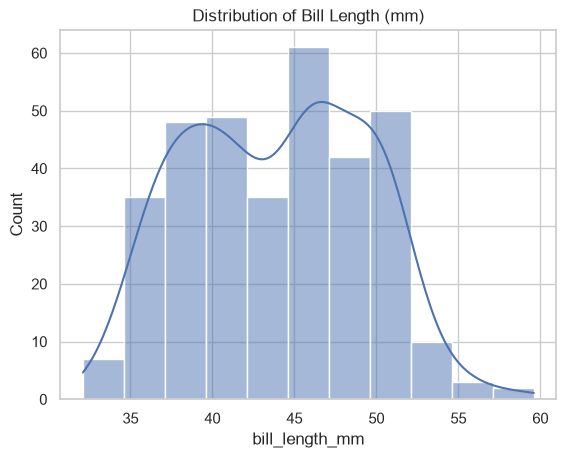

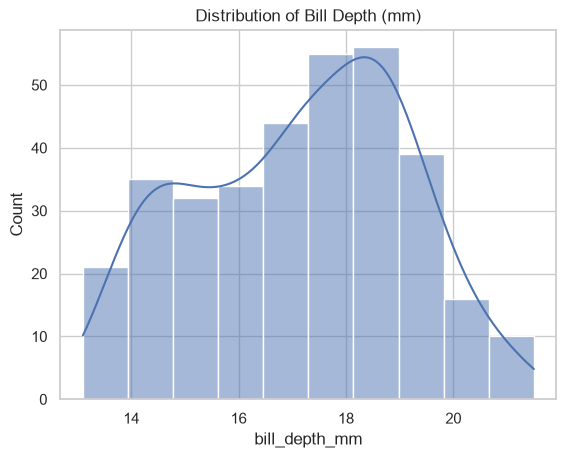

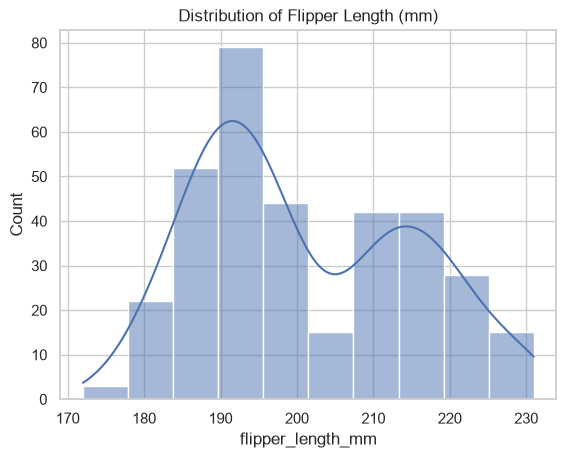

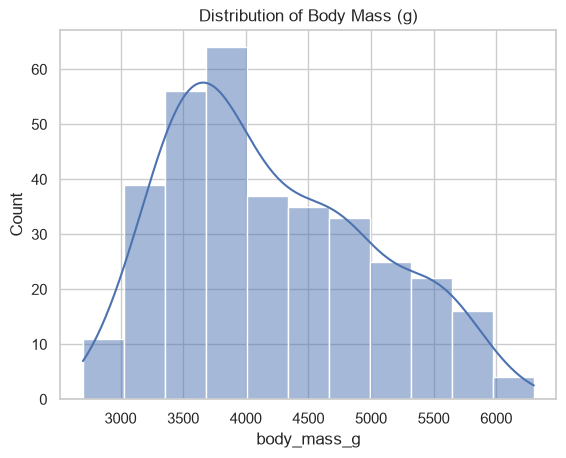

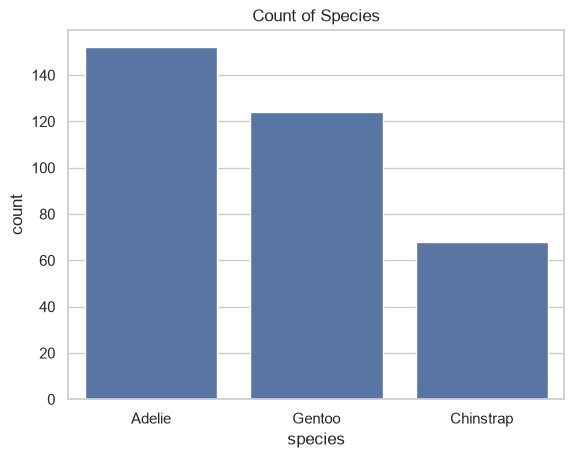

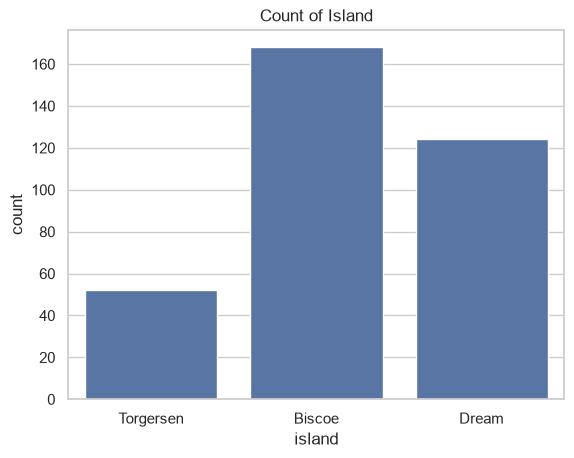

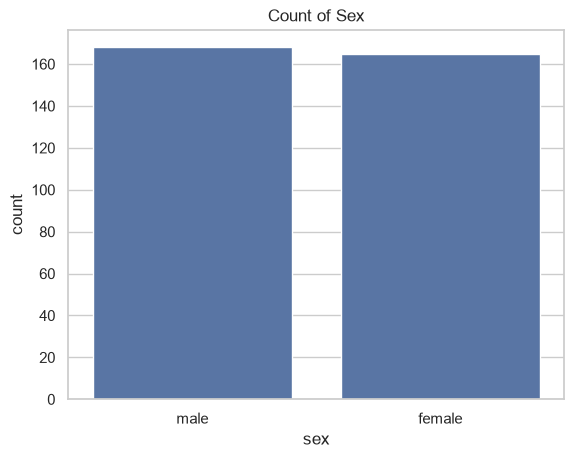

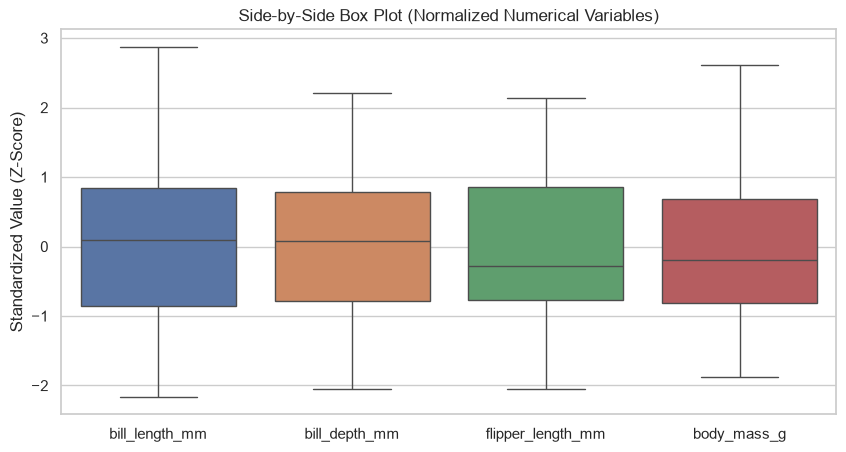

In [30]:
# 1D Histograms for Numerical Variables
plt.figure()
sns.histplot(df['bill_length_mm'].dropna(), kde=True)
plt.title('Distribution of Bill Length (mm)')
plt.show()

plt.figure()
sns.histplot(df['bill_depth_mm'].dropna(), kde=True)
plt.title('Distribution of Bill Depth (mm)')
plt.show()

plt.figure()
sns.histplot(df['flipper_length_mm'].dropna(), kde=True)
plt.title('Distribution of Flipper Length (mm)')
plt.show()

plt.figure()
sns.histplot(df['body_mass_g'].dropna(), kde=True)
plt.title('Distribution of Body Mass (g)')
plt.show()

# Bar Charts for Categorical Variables
plt.figure()
sns.countplot(data=df, x='species')
plt.title('Count of Species')
plt.show()

plt.figure()
sns.countplot(data=df, x='island')
plt.title('Count of Island')
plt.show()

plt.figure()
sns.countplot(data=df, x='sex')
plt.title('Count of Sex')
plt.show()

# All numerical variables side-by-side (Normalized box plot)
num_df = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].dropna()
normalized_df = (num_df - num_df.mean()) / num_df.std()

plt.figure(figsize=(10, 5))
sns.boxplot(data=normalized_df)
plt.title('Side-by-Side Box Plot (Normalized Numerical Variables)')
plt.ylabel('Standardized Value (Z-Score)')
plt.show()

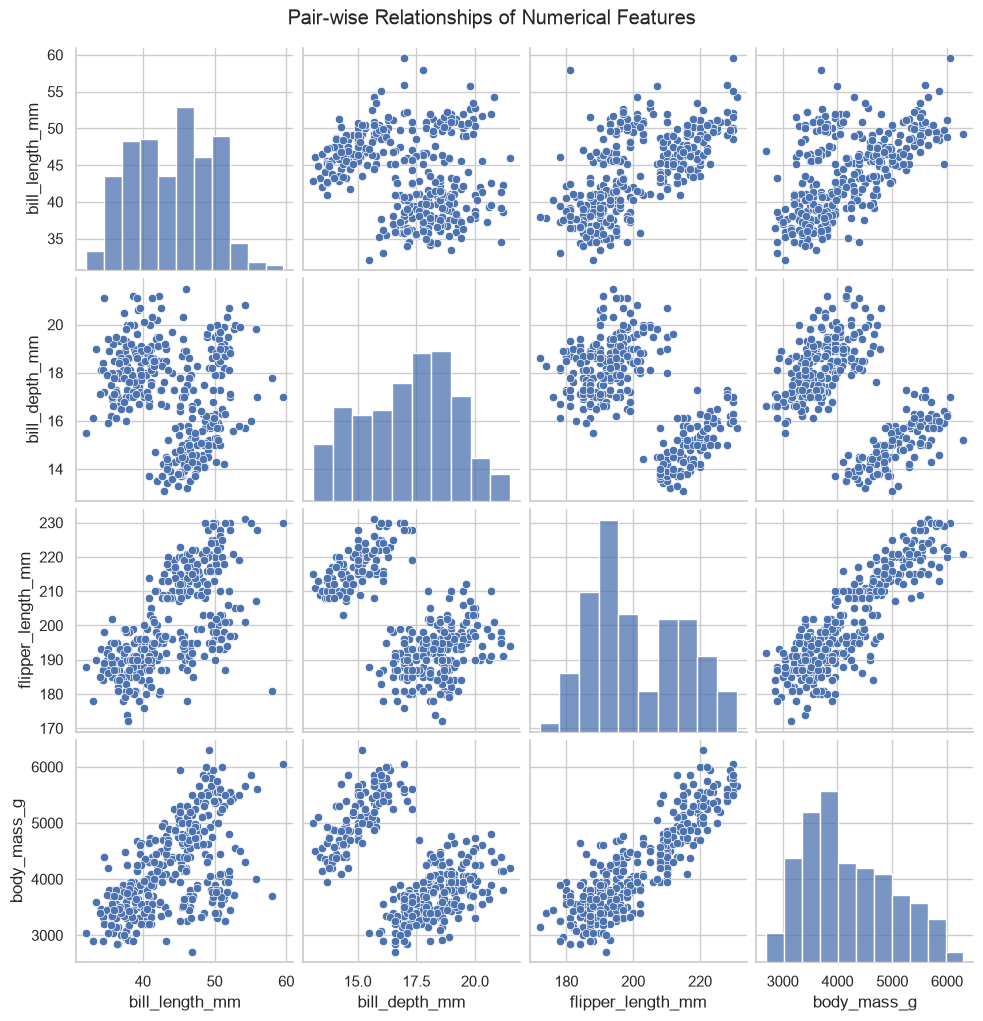

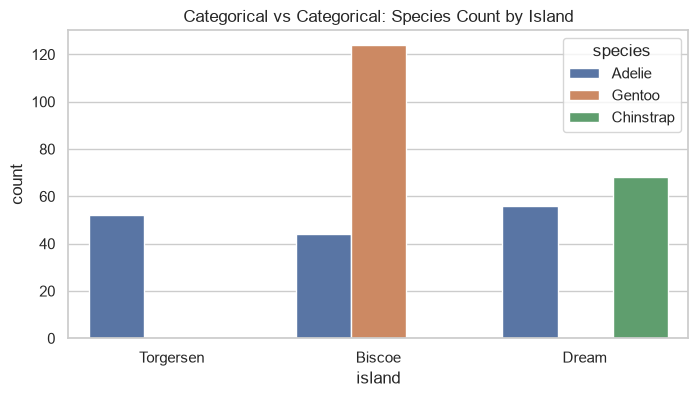

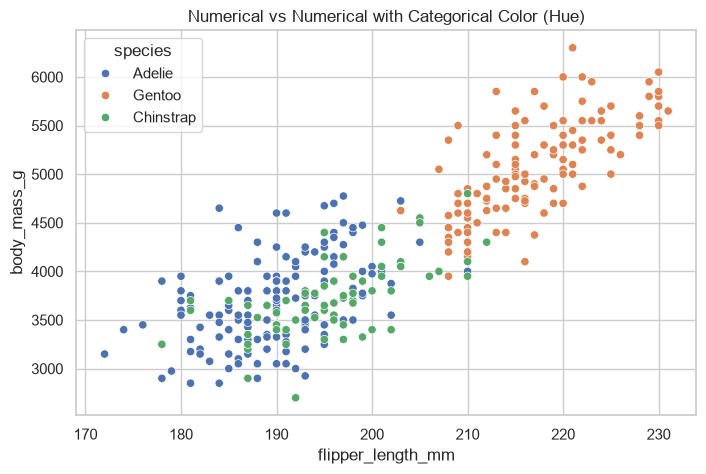

In [31]:
# 1. Matrix of scatter plots for numerical data
sns.pairplot(df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].dropna())
plt.suptitle('Pair-wise Relationships of Numerical Features', y=1.02)
plt.show()

# 2. Categorical vs Categorical: Aggregate species by island
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='island', hue='species')
plt.title('Categorical vs Categorical: Species Count by Island')
plt.show()

# 3. Categorical vs Numerical with Color: Flipper Length vs Body Mass colored by Species
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species')
plt.title('Numerical vs Numerical with Categorical Color (Hue)')
plt.show()

### Summary Report: Palmer Penguins EDA

#### 1. Summary Statistics for Numerical Features
* **Bill Length (`bill_length_mm`):**
  * Min: 32.1 mm
  * Max: 59.6 mm
  * Mean: 43.92 mm
  * Median: 44.45 mm
  * Outliers: 0

* **Bill Depth (`bill_depth_mm`):**
  * Min: 13.1 mm
  * Max: 21.5 mm
  * Mean: 17.15 mm
  * Median: 17.30 mm
  * Outliers: 0

* **Flipper Length (`flipper_length_mm`):**
  * Min: 172 mm
  * Max: 231 mm
  * Mean: 200.92 mm
  * Median: 197.00 mm
  * Outliers: 0

* **Body Mass (`body_mass_g`):**
  * Min: 2,700 g
  * Max: 6,300 g
  * Mean: 4,201.75 g
  * Median: 4,050.00 g
  * Outliers: 0

---

#### 2. Key Findings & Observations
* **Distribution:** Flipper length and body mass have two clear peaks, showing that penguins generally fall into two size groups (smaller vs. larger species).
* **Outliers:** Based on the 1.5 × IQR rule, there are no extreme outliers in any of the primary physical measurements.
* **Correlations:** There is a strong positive relationship between flipper length and body mass, penguins with longer flippers weigh significantly more.
* **Species Comparison:** Gentoo penguins are clearly the largest species in the dataset in terms of body mass and flipper length, while Adelie and Chinstrap penguins are smaller and similar in body weight.